# Week 8 - K-Nearest Neighbors and Distance Metrics

K-Nearest Neighbors (KNN) has no training step and no coefficients: to predict a new sample it finds the *k* closest training samples and takes a vote (classification) or an average (regression). All of the modeling decisions are therefore about **what "closest" means**: the distance metric (Euclidean, Manhattan, Minkowski with any power *p*, cosine), the feature scaling, and *k* itself.

I apply it to all three capstone datasets, one distance question per dataset:

| Dataset | Target | Distance question |
|---|---|---|
| E-commerce (`ecommerce_data.csv`) | `Profit > 0` (same target as Weeks 4-6) | Euclidean vs. Manhattan vs. Minkowski *p*, and does scaling or the number of features change the answer? |
| Amazon reviews (`amazon_review_data.csv`) | negative review (rating 1-2 vs 4-5, as in Week 5) | Cosine vs. Euclidean on word counts and TF-IDF vectors |
| Instacart (`insta_df_sample.csv`) | `reordered` | Euclidean vs. Manhattan on scaled numeric features |

Each metric is judged on 5-fold CV (never on the test set), and the final comparison uses the same stratified split (`random_state=42`) as earlier weeks so the numbers line up with Weeks 4-6. As before, the metric that matters for the imbalanced targets is **F1 on the minority class**, not accuracy.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")
np.random.seed(42)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def scores_row(name, y_true, proba, preds, minority_label):
    return {"model": name, "accuracy": accuracy_score(y_true, preds), "roc_auc": roc_auc_score(y_true, proba),
            "f1_minority": f1_score(y_true, preds, pos_label=minority_label),
            "precision_minority": precision_score(y_true, preds, pos_label=minority_label, zero_division=0),
            "recall_minority": recall_score(y_true, preds, pos_label=minority_label)}
BLUE, ORANGE = "#2a78d6", "#eb6834"

## Part 0 - Warm-up: the reading's questions in code

Before the real data, three of the "Think About It" questions are easy to check directly.

**Q2 - what does Minkowski distance do for huge *p*?** It converges to the **Chebyshev distance** (the single largest coordinate difference). **Q3 - does standardizing remove outliers?** No: it recenters and rescales, it does not delete anything, so a point that was extreme stays extreme (I prove it below, and then show it on the real `Sales` column).

In [2]:
x, y = 3.0, 4.0
print("Minkowski (x=3, y=4):")
for p in [1, 2, 3, 10, 50, 100, 1000, 1_000_000]:
    m = max(x, y)                              # factor out the max to avoid overflow at huge p
    d = m * ((x / m) ** p + (y / m) ** p) ** (1 / p)
    print(f"  p = {p:>9,}: {d:.6f}")
print("  max(x, y) =", max(x, y), "<- the p -> infinity limit (Chebyshev)")

# Standardizing does not remove outliers: 99 ordinary points and one extreme point
v = np.array([0.0] * 99 + [100.0])
z = (v - v.mean()) / v.std()
print(f"\nAfter standardizing: mean {z.mean():.2f}, std {z.std():.2f}, but the extreme point still has z = {z.max():.2f} while the others sit at {z.min():.2f}")

# Cosine ignores magnitude: the reading's egg/bacon documents
a, b = np.array([2, 1]), np.array([4, 2])
cos_d = 1 - a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print(f"\ncosine distance (2,1) vs (4,2) = {cos_d:.4f};  Euclidean distance = {np.linalg.norm(a-b):.3f}")

Minkowski (x=3, y=4):
  p =         1: 7.000000
  p =         2: 5.000000
  p =         3: 4.497941
  p =        10: 4.021974
  p =        50: 4.000000
  p =       100: 4.000000
  p =     1,000: 4.000000
  p = 1,000,000: 4.000000
  max(x, y) = 4.0 <- the p -> infinity limit (Chebyshev)

After standardizing: mean 0.00, std 1.00, but the extreme point still has z = 9.95 while the others sit at -0.10

cosine distance (2,1) vs (4,2) = 0.0000;  Euclidean distance = 2.236


## Part A - E-commerce: is this order profitable?

### A1. Scaling matters for KNN (the reading's height-in-feet vs. weight-in-pounds point)

Same 29 features and the same stratified 75/25 split as Weeks 4-6. `Sales` ranges into the thousands while `Discount` lives between 0 and 0.8, so unscaled Euclidean KNN is almost entirely a `Sales` model, and the discount effect that I found in Weeks 4-6 would be invisible to it. The scaler is fit on the training set only.

In [3]:
df = pd.read_csv("ecommerce_data.csv")
numeric_cols = ["Sales", "Quantity", "Discount"]
categorical_cols = ["Segment", "Region", "Ship Mode", "Category", "Sub-Category"]
X = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True).astype(float)
y = (df["Profit"] > 0).astype(int).values            # 1 = profitable, 0 = unprofitable (minority)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X.shape, f"profitable share {y.mean():.1%}; majority-class baseline accuracy {max(y.mean(), 1 - y.mean()):.3f}")

scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

rows = []
for name, (A, B) in {"unscaled": (X_train.values, X_test.values), "standardized": (Xs_train, Xs_test)}.items():
    knn = KNeighborsClassifier(n_neighbors=5).fit(A, y_train)
    p1 = knn.predict_proba(B)[:, 1]; pr = knn.predict(B)
    rows.append(scores_row(f"KNN k=5, Euclidean, {name}", y_test, p1, pr, 0))
print(pd.DataFrame(rows).set_index("model").round(3))

(3312, 29) profitable share 80.7%; majority-class baseline accuracy 0.807
                                  accuracy  roc_auc  f1_minority  \
model                                                              
KNN k=5, Euclidean, unscaled         0.835    0.745        0.441   
KNN k=5, Euclidean, standardized     0.909    0.927        0.756   

                                  precision_minority  recall_minority  
model                                                                  
KNN k=5, Euclidean, unscaled                   0.635            0.338  
KNN k=5, Euclidean, standardized               0.789            0.725  


### A2. Which distance, and how many neighbors?

I compare Manhattan (*p* = 1), a fractional *p* = 0.5 (the reading's playlist example; it is not a true metric, but it is a valid dissimilarity), 1.5, Euclidean (*p* = 2), 3, 10, and Chebyshev (*p* = infinity), tuning *k* for each with 5-fold CV on ROC AUC. Distances are computed once as a matrix with `scipy` and handed to `KNeighborsClassifier(metric="precomputed")`, which lets me use fractional *p*. I run the whole sweep on two feature sets:

* **All 29 standardized features** (3 numeric + 26 one-hot columns).
* **The 3 numeric features only** (`Sales`, `Quantity`, `Discount`).

The second set tests the curse of dimensionality: with 26 binary columns, most of the squared distance between two orders comes from categories that have little to do with profit.

In [4]:
k_grid = [1, 3, 5, 9, 15, 25, 41]
metrics = {"Manhattan (p=1)": 1, "Minkowski p=0.5": 0.5, "Minkowski p=1.5": 1.5, "Euclidean (p=2)": 2, "Minkowski p=3": 3, "Minkowski p=10": 10, "Chebyshev (p=inf)": np.inf}
num_idx = [list(X.columns).index(c) for c in numeric_cols]

def dist(A, B, p):
    return cdist(A, B, metric="chebyshev") if np.isinf(p) else cdist(A, B, metric="minkowski", p=p)

def sweep(A_tr, A_te, label):
    out, cv_curves = [], {}
    for mname, p in metrics.items():
        D_tr, D_te = dist(A_tr, A_tr, p), dist(A_te, A_tr, p)
        cv = {k: cross_val_score(KNeighborsClassifier(n_neighbors=k, metric="precomputed"), D_tr, y_train, cv=cv5, scoring="roc_auc").mean() for k in k_grid}
        cv_curves[mname] = cv
        k_best = max(cv, key=cv.get)
        knn = KNeighborsClassifier(n_neighbors=k_best, metric="precomputed").fit(D_tr, y_train)
        proba, pred = knn.predict_proba(D_te)[:, 1], knn.predict(D_te)
        r = scores_row(mname, y_test, proba, pred, 0); r.update({"features": label, "best_k": k_best, "cv_auc": cv[k_best]})
        out.append(r)
    return pd.DataFrame(out), cv_curves

res_all, curves_all = sweep(Xs_train, Xs_test, "all 29")
res_num, curves_num = sweep(Xs_train[:, num_idx], Xs_test[:, num_idx], "3 numeric")
cols = ["features", "model", "best_k", "cv_auc", "accuracy", "roc_auc", "f1_minority", "precision_minority", "recall_minority"]
knn_ecom = pd.concat([res_all, res_num])[cols].reset_index(drop=True)
print(knn_ecom.round(3).to_string())

     features              model  best_k  cv_auc  accuracy  roc_auc  f1_minority  precision_minority  recall_minority
0      all 29    Manhattan (p=1)      15   0.947     0.930    0.950        0.801               0.886            0.731
1      all 29    Minkowski p=0.5      25   0.951     0.924    0.950        0.784               0.870            0.712
2      all 29    Minkowski p=1.5      25   0.946     0.917    0.949        0.763               0.847            0.694
3      all 29    Euclidean (p=2)      25   0.944     0.909    0.948        0.739               0.835            0.662
4      all 29      Minkowski p=3      25   0.940     0.908    0.947        0.738               0.823            0.669
5      all 29     Minkowski p=10      25   0.932     0.908    0.942        0.734               0.833            0.656
6      all 29  Chebyshev (p=inf)      15   0.924     0.899    0.938        0.696               0.828            0.600
7   3 numeric    Manhattan (p=1)      41   0.953     0.9

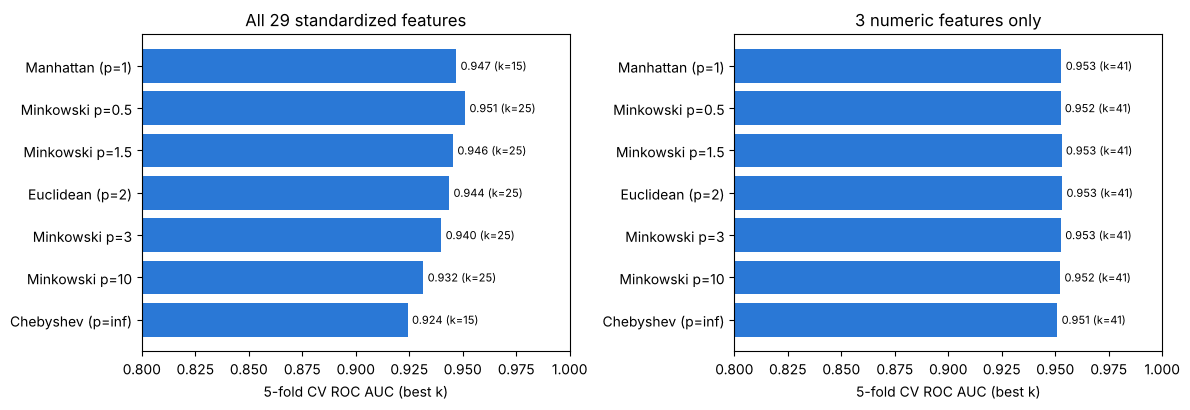

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, res, ttl in [(ax[0], res_all, "All 29 standardized features"), (ax[1], res_num, "3 numeric features only")]:
    a.barh(res["model"][::-1], res["cv_auc"][::-1], color=BLUE)
    for i, (v, k) in enumerate(zip(res["cv_auc"][::-1], res["best_k"][::-1])):
        a.text(v + 0.002, i, f"{v:.3f} (k={k})", va="center", fontsize=8)
    a.set_xlim(0.8, 1.0); a.set_xlabel("5-fold CV ROC AUC (best k)"); a.set_title(ttl)
plt.tight_layout(); plt.show()

### A3. The bias-variance trade-off in *k*

Small *k* follows the training data exactly (at *k* = 1 every training point is its own nearest neighbor, so training accuracy is 1.0 by construction); large *k* averages over so many orders that the local discount structure is washed out. I use the best-performing metric from A2 and compare training accuracy with 5-fold CV AUC across *k*.

Best e-commerce KNN configuration by CV AUC:
features          3 numeric
model       Euclidean (p=2)
best_k                   41
cv_auc             0.953251


  k  train_acc  cv_AUC
  1      0.996   0.855
  2      0.955   0.877
  3      0.952   0.894
  5      0.946   0.914
  9      0.937   0.933
 15      0.933   0.948
 25      0.936   0.948
 41      0.931   0.953
 71      0.924   0.948
121      0.917   0.951
201      0.905   0.946


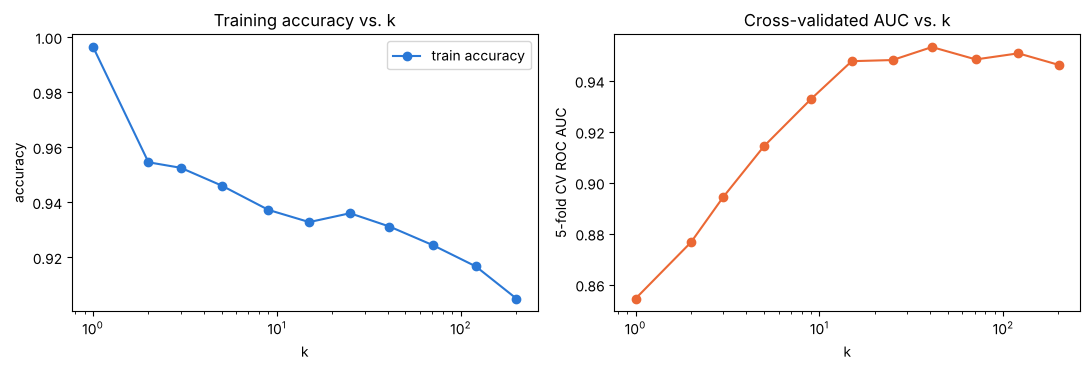

In [6]:
best_row = knn_ecom.sort_values("cv_auc", ascending=False).iloc[0]
print("Best e-commerce KNN configuration by CV AUC:"); print(best_row[["features", "model", "best_k", "cv_auc"]].to_string())
use_num = best_row["features"] == "3 numeric"
p_best = metrics[best_row["model"]]
A_tr = Xs_train[:, num_idx] if use_num else Xs_train
D_tr = dist(A_tr, A_tr, p_best)
ks = [1, 2, 3, 5, 9, 15, 25, 41, 71, 121, 201]
tr_acc, cv_auc = [], []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k, metric="precomputed").fit(D_tr, y_train)
    tr_acc.append(knn.score(D_tr, y_train))
    cv_auc.append(cross_val_score(KNeighborsClassifier(n_neighbors=k, metric="precomputed"), D_tr, y_train, cv=cv5, scoring="roc_auc").mean())
print(pd.DataFrame({"k": ks, "train_acc": tr_acc, "cv_AUC": cv_auc}).round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(ks, tr_acc, "-o", color=BLUE, label="train accuracy"); ax[0].set_xlabel("k"); ax[0].set_ylabel("accuracy"); ax[0].legend(); ax[0].set_title("Training accuracy vs. k")
ax[1].semilogx(ks, cv_auc, "-o", color=ORANGE); ax[1].set_xlabel("k"); ax[1].set_ylabel("5-fold CV ROC AUC"); ax[1].set_title("Cross-validated AUC vs. k")
plt.tight_layout(); plt.show()

### A4. Do standardized data still have outliers?

The reading's third question, on the real data: after standardizing `Sales`, how many orders are still extreme, and how much does a single extreme order dominate a Euclidean distance compared with a Manhattan distance?

In [7]:
z_sales = Xs_train[:, list(X.columns).index("Sales")]
print(f"Standardized Sales: max z = {z_sales.max():.1f}, orders with |z| > 3: {(np.abs(z_sales) > 3).sum()} of {len(z_sales)}")

# one test order, its nearest neighbor under Euclidean vs Manhattan, and each neighbor's largest single-feature gap
i = int(np.argmax(np.abs(Xs_test[:, list(X.columns).index("Sales")])))
for nm, p in [("Euclidean", 2), ("Manhattan", 1)]:
    d = dist(Xs_test[i:i+1], Xs_train, p)[0]; j = int(d.argmin())
    gaps = np.abs(Xs_test[i] - Xs_train[j])
    share = gaps.max() ** 2 / (gaps ** 2).sum() if p == 2 else gaps.max() / gaps.sum()
    print(f"{nm:9s}: nearest neighbor is {d[j]:.2f} away; its largest single-feature gap is {gaps.max():.2f} z-units "
          f"and that one feature supplies {share:.0%} of the {'squared ' if p == 2 else ''}distance")
print("\nTakeaway: Euclidean picks a neighbor whose gaps are spread out and smaller in every feature; Manhattan will accept a neighbor that is far away in just one feature.")

Standardized Sales: max z = 21.7, orders with |z| > 3: 36 of 2484
Euclidean: nearest neighbor is 4.53 away; its largest single-feature gap is 2.54 z-units and that one feature supplies 31% of the squared distance
Manhattan: nearest neighbor is 8.53 away; its largest single-feature gap is 8.53 z-units and that one feature supplies 100% of the distance

Takeaway: Euclidean picks a neighbor whose gaps are spread out and smaller in every feature; Manhattan will accept a neighbor that is far away in just one feature.


## Part B - Amazon reviews: cosine distance on text

Text is the reading's cosine example: a long review and a short review that use the same words in the same proportions should be neighbors. I build the same text target as Week 5 (3-star reviews dropped, negative = rating 1-2, title and body joined) and use the same stratified split.

Two vector representations:

* **Raw word counts** (`CountVectorizer`): vector length grows with review length, so Euclidean distance mostly compares *how long* the reviews are.
* **TF-IDF** (`TfidfVectorizer`, each row L2-normalized to length 1): length is already removed. For unit vectors, squared Euclidean distance = 2 x cosine distance, so Euclidean and cosine should rank neighbors **identically**. I check that claim.

In [8]:
a = pd.read_csv("amazon_review_data.csv")
a = a[a["rating"] != 3].copy()
a["negative"] = (a["rating"] <= 2).astype(int)
a["full"] = a["title"].fillna("") + ". " + a["text"].fillna("")
tr, te = train_test_split(a, test_size=0.25, random_state=42, stratify=a["negative"])
ya_tr, ya_te = tr["negative"].values, te["negative"].values
print(a.shape, f"negative share {a['negative'].mean():.1%}")

cnt = CountVectorizer(stop_words="english", min_df=3, max_features=8000)
tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_features=8000, ngram_range=(1, 2), sublinear_tf=True)
Xc_tr, Xc_te = cnt.fit_transform(tr["full"]), cnt.transform(te["full"])
Xt_tr, Xt_te = tfidf.fit_transform(tr["full"]), tfidf.transform(te["full"])

# Some very short reviews have NO vocabulary terms left (all-zero vector). Their Euclidean distance to any query is exactly the query's length (1.0 for TF-IDF),
# which is *smaller* than the distance to most real reviews, so empty training reviews would become everybody's nearest neighbors. Drop them from the neighbor pool.
empty_c, empty_t = (Xc_tr.getnnz(axis=1) == 0), (Xt_tr.getnnz(axis=1) == 0)
print(f"empty training vectors: word counts {empty_c.sum()}, TF-IDF {empty_t.sum()} of {Xc_tr.shape[0]}")
reps = {"word counts": (Xc_tr[~empty_c], ya_tr[~empty_c], Xc_te), "TF-IDF": (Xt_tr[~empty_t], ya_tr[~empty_t], Xt_te)}

# check: on TF-IDF (unit-length rows), Euclidean and cosine give the same neighbors
A_pool, y_pool, A_q = reps["TF-IDF"]
sub = A_q[:200]
nn_e = KNeighborsClassifier(n_neighbors=5, metric="euclidean", algorithm="brute").fit(A_pool, y_pool).kneighbors(sub, return_distance=False)
nn_c = KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute").fit(A_pool, y_pool).kneighbors(sub, return_distance=False)
print("share of identical neighbor sets (Euclidean vs cosine on TF-IDF, empty rows removed):", np.mean([set(r1) == set(r2) for r1, r2 in zip(nn_e, nn_c)]))

(9373, 13) negative share 12.4%


empty training vectors: word counts 15, TF-IDF 16 of 7029
share of identical neighbor sets (Euclidean vs cosine on TF-IDF, empty rows removed): 0.975


In [9]:
k_text = [1, 5, 15, 31, 61]
rows = []
for rep, (A_tr, y_rep, A_te) in reps.items():
    for metric in ["euclidean", "manhattan", "cosine"]:
        if rep == "TF-IDF" and metric == "manhattan": continue
        cv = {k: cross_val_score(KNeighborsClassifier(n_neighbors=k, metric=metric, algorithm="brute"), A_tr, y_rep, cv=cv5, scoring="roc_auc", n_jobs=-1).mean() for k in k_text}
        kb = max(cv, key=cv.get)
        knn = KNeighborsClassifier(n_neighbors=kb, metric=metric, algorithm="brute").fit(A_tr, y_rep)
        proba = knn.predict_proba(A_te)[:, 1]; pred = knn.predict(A_te)
        r = scores_row(f"{rep}, {metric}", ya_te, proba, pred, 1); r.update({"best_k": kb, "cv_auc": cv[kb]}); rows.append(r)
knn_text = pd.DataFrame(rows)[["model", "best_k", "cv_auc", "accuracy", "roc_auc", "f1_minority", "precision_minority", "recall_minority"]]
print(knn_text.round(3).to_string(index=False))

                 model  best_k  cv_auc  accuracy  roc_auc  f1_minority  precision_minority  recall_minority
word counts, euclidean      31   0.821     0.878    0.815        0.040                 1.0            0.021
word counts, manhattan      31   0.817     0.877    0.821        0.014                 1.0            0.007
   word counts, cosine      61   0.876     0.885    0.875        0.141                 1.0            0.076
     TF-IDF, euclidean      61   0.918     0.895    0.932        0.263                 1.0            0.151
        TF-IDF, cosine      61   0.918     0.895    0.932        0.263                 1.0            0.151


### B2. KNN has no `class_weight` - fixing the minority class with a threshold

A majority vote among *k* neighbors rarely says "negative" when only 12% of reviews are negative, so recall on the minority class is poor at the default threshold of 0.5. Instead of touching the test set, I choose the probability threshold on **out-of-fold predictions on the training set** (maximizing F1 for the negative class), then apply that fixed threshold once to the test set.

In [10]:
metric = "cosine"; rep_tr, y_rep_tr, rep_te = reps["TF-IDF"]
kb = int(knn_text.query("model == 'TF-IDF, cosine'")["best_k"].iloc[0])
oof = cross_val_predict(KNeighborsClassifier(n_neighbors=kb, metric=metric, algorithm="brute"), rep_tr, y_rep_tr, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
ths = np.linspace(0.05, 0.6, 23)
f1s = [f1_score(y_rep_tr, oof >= t) for t in ths]
t_star = ths[int(np.argmax(f1s))]
print(f"best threshold on training out-of-fold predictions: {t_star:.2f} (OOF F1 {max(f1s):.3f})")
knn = KNeighborsClassifier(n_neighbors=kb, metric=metric, algorithm="brute").fit(rep_tr, y_rep_tr)
proba = knn.predict_proba(rep_te)[:, 1]
text_final = scores_row(f"TF-IDF cosine KNN (k={kb}), threshold {t_star:.2f}", ya_te, proba, (proba >= t_star).astype(int), 1)
print(pd.DataFrame([text_final]).set_index("model").round(3).to_string())

best threshold on training out-of-fold predictions: 0.20 (OOF F1 0.648)


                                          accuracy  roc_auc  f1_minority  precision_minority  recall_minority
model                                                                                                        
TF-IDF cosine KNN (k=61), threshold 0.20     0.922    0.932        0.682                0.69            0.674


## Part C - Instacart: will this item be reordered?

Only genuinely numeric columns belong in a distance calculation, so I use `order_number`, `order_dow`, `order_hour_of_day`, `add_to_cart_order`, and `days_since_prior_order`. The aisle and department codes that Week 6's forest used are *labels*: the code 83 is not "closer" to 84 than to 5, so a distance on them would be meaningless. (Hour of day and day of week are also circular, which a plain distance ignores; I note that as a limitation.) `days_since_prior_order` is missing exactly on first orders (Week 6), so I fill it with 0 and add an `is_first_order` indicator. Features are standardized on the training set.

In [11]:
ins = pd.read_csv("insta_df_sample.csv")
ins["is_first_order"] = ins["days_since_prior_order"].isna().astype(float)
ins["days_since_prior_order"] = ins["days_since_prior_order"].fillna(0)
feats = ["order_number", "order_dow", "order_hour_of_day", "add_to_cart_order", "days_since_prior_order", "is_first_order"]
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(ins[feats], ins["reordered"].values, test_size=0.25, random_state=42, stratify=ins["reordered"])
sci = StandardScaler().fit(Xi_tr); Xis_tr, Xis_te = sci.transform(Xi_tr), sci.transform(Xi_te)
print(Xi_tr.shape, f"reordered share {ins['reordered'].mean():.1%}; majority-class baseline accuracy {ins['reordered'].mean():.3f}")

ki = [5, 15, 31, 61, 101, 201]
rows = []
for metric in ["euclidean", "manhattan", "chebyshev"]:
    cv = {k: cross_val_score(KNeighborsClassifier(n_neighbors=k, metric=metric), Xis_tr, yi_tr, cv=cv5, scoring="roc_auc", n_jobs=-1).mean() for k in ki}
    kb_i = max(cv, key=cv.get)
    knn = KNeighborsClassifier(n_neighbors=kb_i, metric=metric).fit(Xis_tr, yi_tr)
    proba = knn.predict_proba(Xis_te)[:, 1]; pred = knn.predict(Xis_te)
    r = scores_row(f"KNN {metric}", yi_te, proba, pred, 0); r.update({"best_k": kb_i, "cv_auc": cv[kb_i]}); rows.append(r)
knn_insta = pd.DataFrame(rows)[["model", "best_k", "cv_auc", "accuracy", "roc_auc", "f1_minority", "precision_minority", "recall_minority"]]
print(knn_insta.round(3).to_string(index=False))

(11250, 6) reordered share 59.2%; majority-class baseline accuracy 0.592


        model  best_k  cv_auc  accuracy  roc_auc  f1_minority  precision_minority  recall_minority
KNN euclidean     201   0.737     0.691    0.747        0.498               0.738            0.375
KNN manhattan     201   0.741     0.699    0.751        0.520               0.745            0.399
KNN chebyshev     201   0.727     0.692    0.739        0.488               0.756            0.360


## Summary: KNN against the earlier weeks

The rows from Weeks 4-6 are copied from my earlier notebook outputs (same splits), so they are directly comparable.

In [12]:
best_ecom = knn_ecom.sort_values("cv_auc", ascending=False).iloc[0]
summary = pd.DataFrame([
    {"dataset": "E-commerce", "model": "Logistic regression (Week 4)", "roc_auc": 0.976, "f1_minority": 0.804},
    {"dataset": "E-commerce", "model": "RBF SVM (Week 5)", "roc_auc": 0.965, "f1_minority": 0.825},
    {"dataset": "E-commerce", "model": "Random forest (Week 6)", "roc_auc": 0.980, "f1_minority": 0.844},
    {"dataset": "E-commerce", "model": f"KNN: {best_ecom['model']}, {best_ecom['features']}, k={best_ecom['best_k']}", "roc_auc": best_ecom["roc_auc"], "f1_minority": best_ecom["f1_minority"]},
    {"dataset": "Amazon", "model": "TF-IDF + linear SVM (Week 5)", "roc_auc": 0.957, "f1_minority": 0.752},
    {"dataset": "Amazon", "model": text_final["model"], "roc_auc": text_final["roc_auc"], "f1_minority": text_final["f1_minority"]},
    {"dataset": "Instacart", "model": "Random forest (Week 6)", "roc_auc": 0.783, "f1_minority": 0.601},
    {"dataset": "Instacart", "model": f"KNN: {knn_insta.sort_values('cv_auc', ascending=False).iloc[0]['model']}", "roc_auc": knn_insta.sort_values('cv_auc', ascending=False).iloc[0]["roc_auc"], "f1_minority": knn_insta.sort_values('cv_auc', ascending=False).iloc[0]["f1_minority"]},
])
print(summary.round(3).to_string(index=False))

   dataset                                    model  roc_auc  f1_minority
E-commerce             Logistic regression (Week 4)    0.976        0.804
E-commerce                         RBF SVM (Week 5)    0.965        0.825
E-commerce                   Random forest (Week 6)    0.980        0.844
E-commerce    KNN: Euclidean (p=2), 3 numeric, k=41    0.951        0.790
    Amazon             TF-IDF + linear SVM (Week 5)    0.957        0.752
    Amazon TF-IDF cosine KNN (k=61), threshold 0.20    0.932        0.682
 Instacart                   Random forest (Week 6)    0.783        0.601
 Instacart                       KNN: KNN manhattan    0.751        0.520


## Conclusions

**Scaling is not optional for KNN.** On the e-commerce data, standardizing the same 29 features with the same *k* = 5 moved test ROC AUC from 0.745 to 0.927 and F1 on unprofitable orders from 0.441 to 0.756. Without scaling, `Sales` (in the thousands) swamps `Discount` (0 to 0.8), so the model cannot see the discount effect that Weeks 4-6 identified as the main driver.

**The distance metric mattered when there were many features and barely mattered when there were few.**
* On all 29 standardized features, 5-fold CV AUC fell steadily as *p* grew: 0.951 (*p* = 0.5), 0.947 (Manhattan), 0.944 (Euclidean), 0.940 (*p* = 3), 0.932 (*p* = 10), 0.924 (Chebyshev). Test F1 on the unprofitable class followed the same pattern, from 0.801 for Manhattan to 0.739 for Euclidean and 0.696 for Chebyshev. This is consistent with the reading's argument: `Sales` has outliers up to z = 21.7 (36 of 2,484 training orders have |z| > 3), and a higher *p* lets a single extreme feature dominate the distance (in A4, one `Sales` gap supplied 31% of the squared Euclidean distance to the nearest neighbor).
* On the 3 numeric features only, all seven metrics landed within 0.951-0.953 CV AUC. Dropping the 26 one-hot columns *improved* Euclidean KNN (CV AUC 0.944 to 0.953, and the best *k* rose from 25 to 41), so some of the earlier gap was the curse of dimensionality, not the metric itself. KNN has no way to learn which features matter, so irrelevant columns directly add noise to every distance.

**Bias-variance in *k*.** With Euclidean distance on the 3 numeric features, *k* = 1 gives training accuracy 0.996 but CV AUC of only 0.855; CV AUC peaks at 0.953 at *k* = 41 and slips to 0.946 by *k* = 201 as the neighborhoods get too wide.

**Standardizing does not remove outliers** (shown on toy data in Part 0 and on `Sales` in A4). Manhattan accepted a nearest neighbor whose single `Sales` gap was 8.53 z-units (100% of its distance); Euclidean chose one with a largest gap of 2.54, matching the reading's point about which metric tolerates a single outlier dimension.

**Cosine distance on text worked as the reading predicts.**
* On raw word counts, cosine beat Euclidean clearly (CV AUC 0.876 vs 0.821; test AUC 0.875 vs 0.815), because Euclidean mostly compares review length.
* On TF-IDF, whose rows are unit length, Euclidean and cosine are equivalent: 97.5% of 200 test reviews had identical 5-neighbor sets (the rest are ties), and the results matched (CV AUC 0.918, test AUC 0.932, F1 0.263).
* An unexpected pitfall: 16 of 7,029 training reviews had an all-zero TF-IDF vector. Their Euclidean distance to any query is exactly 1, which is smaller than the distance to most real reviews, so they became everyone's nearest neighbors until I removed them. (Cosine did not have this problem, since it gives zero vectors distance 1, too.)
* KNN has no `class_weight`, so at the default threshold it found only 15% of the negative reviews (F1 0.263). Choosing the threshold on out-of-fold training predictions (0.20) lifted test F1 to 0.682 (precision 0.690, recall 0.674) without touching the test set.

**Instacart.** Manhattan (CV AUC 0.741, test AUC 0.751, F1 0.520) was slightly ahead of Euclidean (0.737, 0.747, 0.498) and Chebyshev (0.727, 0.739, 0.488). The best *k* was 201, the edge of my grid, which says the signal is diffuse and a larger *k* might help a little; I did not extend the grid.

### Expected vs. unexpected
* **Expected:** scaling mattered enormously; cosine beat Euclidean on word counts; a small *k* overfit and a very large *k* underfit; lower *p* handled the outlier-heavy `Sales` column better.
* **Unexpected:** (1) the 26 one-hot columns *hurt* the e-commerce KNN, so a "simpler" 3-feature KNN did as well as the 29-feature one on CV AUC; (2) all-zero text vectors silently hijacked Euclidean neighbors; (3) Euclidean and cosine gave the same answer on TF-IDF (obvious in hindsight, since for unit vectors squared Euclidean distance is twice the cosine distance).

### How KNN compares with Weeks 4-6
The best CV-selected e-commerce KNN (3 numeric features, Euclidean, *k* = 41) reached test AUC 0.951 and F1 0.790, behind logistic regression (0.976, 0.804), the RBF SVM (F1 0.825), and the random forest (0.980, 0.844). The Manhattan KNN on all 29 features had a slightly higher test F1 (0.801), but I selected configurations by CV AUC, not by test F1, so the summary table reports the first. On Amazon text the cosine KNN (F1 0.682, AUC 0.932) trailed the linear SVM (0.752, 0.957), and on Instacart Manhattan KNN (AUC 0.751) trailed the random forest (0.783, which also used aisle and department). KNN's advantage is that it needs no model, but it pays for that at prediction time (every query scans the training set), cannot ignore irrelevant features, and is the most sensitive of all the models to scaling and metric choice.

**For the capstone:** KNN is useful as a similarity-based baseline and as the basis for the **recommender** in my proposal, where "customers who bought similar items" is a nearest-neighbor question. The text experiments suggest cosine on TF-IDF vectors as the starting similarity measure, and the e-commerce experiments suggest keeping the feature set small and standardized.